# E-Commerce Sales Data Analysis Using Python

## 1. Project Introduction

This project aims to analyze online retail transaction data using Python to identify sales trends, evaluate product performance, and understand customer purchasing patterns.

## 2. Project Objective

The main objective is to analyze real-world e-commerce data, clean and prepare the dataset, perform data analysis, and create meaningful visualizations to extract useful insights.

## 3. Dataset Source

UCI Machine Learning Repository – Online Retail Dataset.

In [53]:

# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [54]:

import urllib.request

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"

urllib.request.urlretrieve(url, "online_retail.zip")

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [55]:

import zipfile

with zipfile.ZipFile("online_retail.zip", "r") as zip_ref:
    zip_ref.extractall("retail_data")

print("Dataset extracted successfully!")


Dataset extracted successfully!


In [56]:

import pandas as pd

df = pd.read_excel("retail_data/Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Rows: 541909
Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [57]:

# Display column names and data types

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [58]:

# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)


Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [59]:

# Calculate missing values percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Values Percentage:")
print(missing_percentage.round(2))


Missing Values Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [60]:

# Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)


Number of Duplicate Rows: 5268


In [61]:

# Generate descriptive statistics

df.describe()


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


### Data Cleaning – Removing Duplicate Records

Duplicate records were identified in the dataset. These records were removed to avoid counting the same transaction more than once and to improve data quality.

In [62]:

# Remove duplicate rows

df = df.drop_duplicates()

# Check the dataset after removing duplicates

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())


Dataset shape after removing duplicates: (536641, 8)
Remaining duplicate rows: 0


In [63]:

# Check quantity values

print("Negative Quantity:", (df['Quantity'] < 0).sum())
print("Zero Quantity:", (df['Quantity'] == 0).sum())
print("Positive Quantity:", (df['Quantity'] > 0).sum())


Negative Quantity: 10587
Zero Quantity: 0
Positive Quantity: 526054


In [64]:

# Check unit price values

print("Negative UnitPrice:", (df['UnitPrice'] < 0).sum())
print("Zero UnitPrice:", (df['UnitPrice'] == 0).sum())
print("Positive UnitPrice:", (df['UnitPrice'] > 0).sum())


Negative UnitPrice: 2
Zero UnitPrice: 2510
Positive UnitPrice: 534129


In [65]:

# Check cancelled invoices

cancelled_invoices = df['InvoiceNo'].astype(str).str.startswith('C')

print("Cancelled Invoice Rows:", cancelled_invoices.sum())


Cancelled Invoice Rows: 9251


In [66]:

# Display records with negative prices

df[df['UnitPrice'] < 0][
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'Country']
]


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
299983,A563186,B,Adjust bad debt,1,-11062.06,United Kingdom
299984,A563187,B,Adjust bad debt,1,-11062.06,United Kingdom


In [67]:

# Display records with zero prices

df[df['UnitPrice'] == 0][
    ['InvoiceNo', 'StockCode', 'Description',
     'Quantity', 'UnitPrice', 'Country']
].head(10)


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Country
622,536414,22139,NaN,56,0.0,United Kingdom
1970,536545,21134,NaN,1,0.0,United Kingdom
1971,536546,22145,NaN,1,0.0,United Kingdom
1972,536547,37509,NaN,1,0.0,United Kingdom
1987,536549,85226A,NaN,1,0.0,United Kingdom
1988,536550,85044,NaN,1,0.0,United Kingdom
2024,536552,20950,NaN,1,0.0,United Kingdom
2025,536553,37461,NaN,3,0.0,United Kingdom
2026,536554,84670,NaN,23,0.0,United Kingdom
2406,536589,21777,NaN,-10,0.0,United Kingdom


In [68]:

# Compare cancelled invoices and negative quantities

print("Cancelled invoices with negative quantity:",
      (cancelled_invoices & (df['Quantity'] < 0)).sum())

print("Negative quantities in non-cancelled invoices:",
      ((~cancelled_invoices) & (df['Quantity'] < 0)).sum())


Cancelled invoices with negative quantity: 9251
Negative quantities in non-cancelled invoices: 1336


### Handling Invalid Records

Cancelled invoices and records with negative unit prices were identified during data inspection. These records will be excluded from the main sales analysis, while potential returns and zero-priced transactions will be retained for further investigation.

In [69]:

# Create a working copy of the dataset

df_clean = df.copy()

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean['InvoiceNo'].astype(str).str.startswith('C')
]

# Remove records with negative unit prices
df_clean = df_clean[df_clean['UnitPrice'] >= 0]

print("Original dataset:", df.shape)
print("Dataset after cleaning:", df_clean.shape)

print("Remaining cancelled invoices:",
      df_clean['InvoiceNo'].astype(str).str.startswith('C').sum())

print("Remaining negative prices:",
      (df_clean['UnitPrice'] < 0).sum())


Original dataset: (536641, 8)
Dataset after cleaning: (527388, 8)
Remaining cancelled invoices: 0
Remaining negative prices: 0


In [70]:
# Check missing product descriptions

missing_description = df_clean['Description'].isna()

print("Missing descriptions:",
      missing_description.sum())

print("Missing descriptions with zero price:",
      ((missing_description) & (df_clean['UnitPrice'] == 0)).sum())

print("Missing descriptions with positive price:",
      ((missing_description) & (df_clean['UnitPrice'] > 0)).sum())

Missing descriptions: 1454
Missing descriptions with zero price: 1454
Missing descriptions with positive price: 0


In [71]:
# Fill missing product descriptions

df_clean['Description'] = df_clean['Description'].fillna('Unknown Product')

print("Missing descriptions after cleaning:",
      df_clean['Description'].isna().sum())

Missing descriptions after cleaning: 0


In [72]:
print("Missing Customer IDs:",
      df_clean['CustomerID'].isna().sum())

print("Missing Customer IDs Percentage:",
      round(df_clean['CustomerID'].isna().mean() * 100, 2), "%")

Missing Customer IDs: 134656
Missing Customer IDs Percentage: 25.53 %


In [73]:
# Calculate total sales for each transaction

df_clean['Sales'] = df_clean['Quantity'] * df_clean['UnitPrice']

print("Sales column added successfully!")

df_clean[['Quantity', 'UnitPrice', 'Sales']].head()

Sales column added successfully!


,Quantity,UnitPrice,Sales
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [74]:
print("Final Dataset Shape:", df_clean.shape)

print("\nDataset Information:")
df_clean.info()

print("\nStatistical Summary:")
df_clean.describe()

Final Dataset Shape: (527388, 9)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 527388 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    527388 non-null  object        
 1   StockCode    527388 non-null  object        
 2   Description  527388 non-null  object        
 3   Quantity     527388 non-null  int64         
 4   InvoiceDate  527388 non-null  datetime64[ns]
 5   UnitPrice    527388 non-null  float64       
 6   CustomerID   392732 non-null  float64       
 7   Country      527388 non-null  object        
 8   Sales        527388 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 40.2+ MB

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID,Sales
count,527388.000000,527388,527388.000000,392732.000000,527388.000000
mean,10.311308,2011-07-04 12:20:53.819200,3.903904,15287.734822,20.178902
min,-9600.000000,2010-12-01 08:26:00,0.000000,12346.000000,-0.000000
25%,1.000000,2011-03-28 11:49:00,1.250000,13955.000000,3.780000
50%,3.000000,2011-07-19 15:55:00,2.080000,15150.000000,9.900000
75%,11.000000,2011-10-19 10:56:00,4.130000,16791.000000,17.700000
max,80995.000000,2011-12-09 12:50:00,13541.330000,18287.000000,168469.600000
std,160.367588,NaN,36.008048,1713.567773,271.049850


In [75]:
# Calculate revenue metrics

gross_sales = df_clean.loc[df_clean['Sales'] > 0, 'Sales'].sum()

total_returns = abs(
    df_clean.loc[df_clean['Sales'] < 0, 'Sales'].sum()
)

net_sales = df_clean['Sales'].sum()

print("Gross Sales:", round(gross_sales, 2))
print("Total Returns:", round(total_returns, 2))
print("Net Sales:", round(net_sales, 2))

Gross Sales: 10642110.8
Total Returns: 0.0
Net Sales: 10642110.8


In [76]:
# Inspect returned transactions

returns_df = df_clean[df_clean['Quantity'] < 0]

print("Number of return records:", len(returns_df))

print("Returns with positive unit price:",
      (returns_df['UnitPrice'] > 0).sum())

print("Returns with zero unit price:",
      (returns_df['UnitPrice'] == 0).sum())

print("Total return value:",
      returns_df['Sales'].sum())

returns_df[['InvoiceNo', 'Description', 'Quantity',
            'UnitPrice', 'Sales']].head(10)

Number of return records: 1336
Returns with positive unit price: 0
Returns with zero unit price: 1336
Total return value: 0.0


,InvoiceNo,Description,Quantity,UnitPrice,Sales
2406,536589,Unknown Product,-10,0.0,-0.0
4347,536764,Unknown Product,-38,0.0,-0.0
7188,536996,Unknown Product,-20,0.0,-0.0
7189,536997,Unknown Product,-20,0.0,-0.0
7190,536998,Unknown Product,-6,0.0,-0.0
7192,537000,Unknown Product,-22,0.0,-0.0
7193,537001,Unknown Product,-6,0.0,-0.0
7195,537003,Unknown Product,-2,0.0,-0.0
7196,537004,Unknown Product,-30,0.0,-0.0
7197,537005,Unknown Product,-70,0.0,-0.0


In [77]:
# Analyze sales by country

country_sales = (
    df_clean.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Sales:")
print(country_sales.head(10).round(2))

Top 10 Countries by Sales:
Country
United Kingdom    9001744.09
Netherlands        285446.34
EIRE               283140.52
Germany            228678.40
France             209625.37
Australia          138453.81
Spain               61558.56
Switzerland         57067.60
Belgium             41196.34
Sweden              38367.83
Name: Sales, dtype: float64


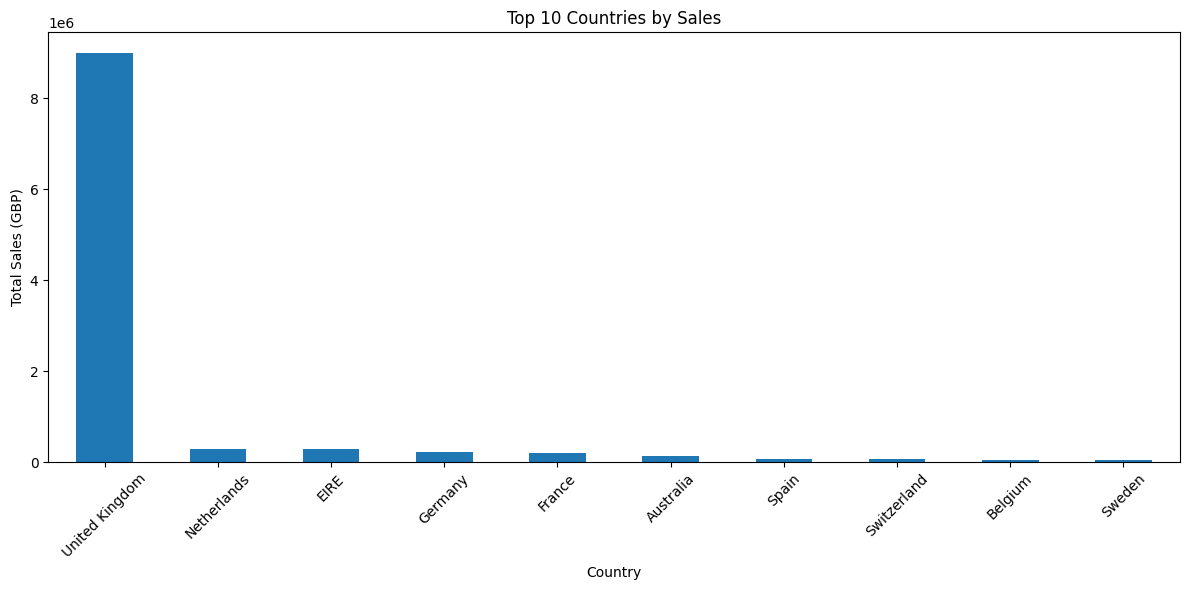

In [78]:
# Top 10 countries by sales - Bar Chart

top_10_countries = country_sales.head(10)

plt.figure(figsize=(12, 6))

top_10_countries.plot(kind='bar')

plt.title('Top 10 Countries by Sales')
plt.xlabel('Country')
plt.ylabel('Total Sales (GBP)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [79]:
# Top 10 products by sales

product_sales = (
    df_clean[df_clean['Sales'] > 0]
    .groupby('Description')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Products by Sales:")
print(product_sales.head(10).round(2))

Top 10 Products by Sales:
Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Sales, dtype: float64


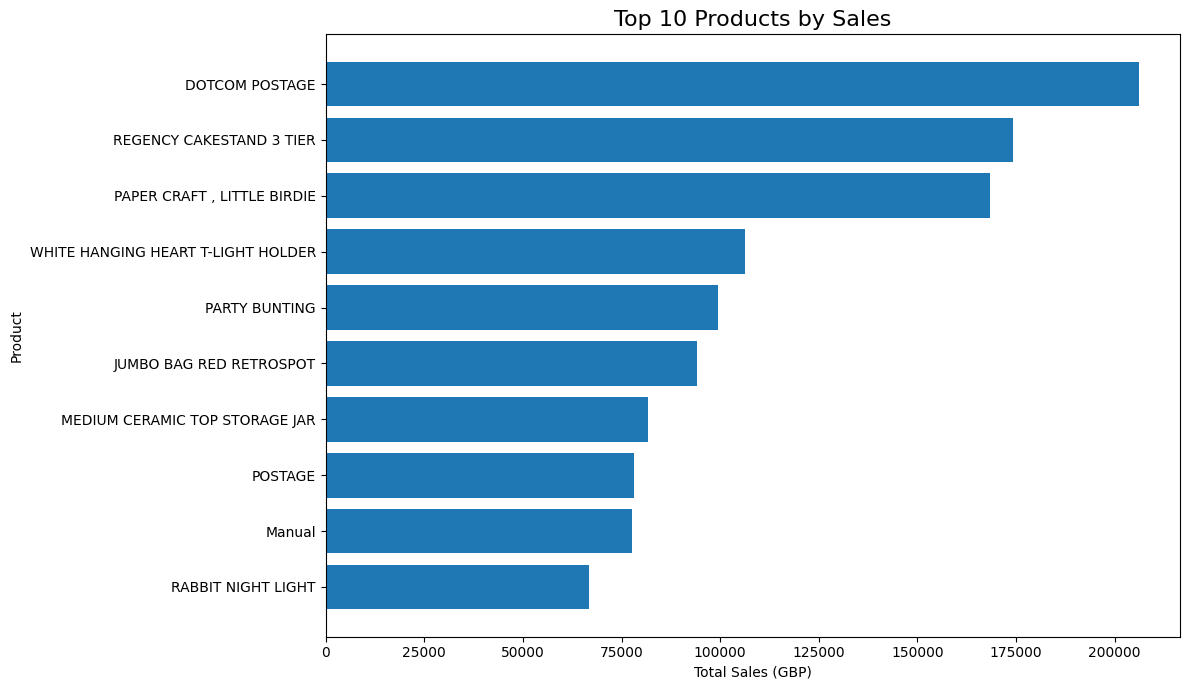

In [80]:
# Top 10 Products by Sales - Bar Chart

top_10_products = product_sales.head(10).sort_values()

plt.figure(figsize=(12, 7))

plt.barh(top_10_products.index, top_10_products.values)

plt.title('Top 10 Products by Sales', fontsize=16)
plt.xlabel('Total Sales (GBP)')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [81]:
# Monthly Sales Analysis

df_clean['Month'] = df_clean['InvoiceDate'].dt.to_period('M')

monthly_sales = (
    df_clean.groupby('Month')['Sales']
    .sum()
)

print("Monthly Sales:")
print(monthly_sales.round(2))

Monthly Sales:
Month
2010-12     821452.73
2011-01     689811.61
2011-02     522545.56
2011-03     716215.26
2011-04     536968.49
2011-05     769296.61
2011-06     760547.01
2011-07     718076.12
2011-08     757841.38
2011-09    1056435.19
2011-10    1151263.73
2011-11    1503866.78
2011-12     637790.33
Freq: M, Name: Sales, dtype: float64


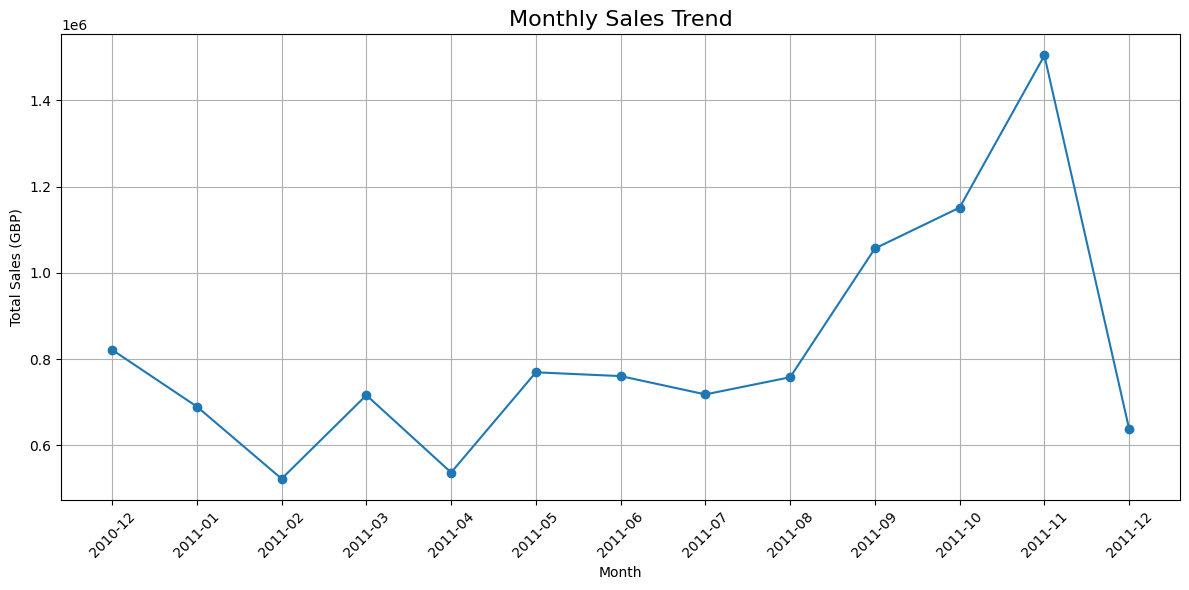

In [82]:
# Monthly Sales Trend - Line Chart

plt.figure(figsize=(12, 6))

plt.plot(monthly_sales.index.astype(str),
         monthly_sales.values,
         marker='o')

plt.title('Monthly Sales Trend', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Sales (GBP)')

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [83]:
# Identify highest and lowest sales months

highest_month = monthly_sales.idxmax()
lowest_month = monthly_sales.idxmin()

print("Highest Sales Month:", highest_month)
print("Highest Sales Value:", round(monthly_sales.max(), 2))

print("\nLowest Sales Month:", lowest_month)
print("Lowest Sales Value:", round(monthly_sales.min(), 2))

Highest Sales Month: 2011-11
Highest Sales Value: 1503866.78

Lowest Sales Month: 2011-02
Lowest Sales Value: 522545.56


In [84]:
# Invoice Analysis

invoice_sales = (
    df_clean.groupby('InvoiceNo')['Sales']
    .sum()
)

total_invoices = df_clean['InvoiceNo'].nunique()
average_invoice = invoice_sales.mean()
highest_invoice = invoice_sales.max()

print("Total Invoices:", total_invoices)
print("Average Invoice Value:", round(average_invoice, 2), "GBP")
print("Highest Invoice Value:", round(highest_invoice, 2), "GBP")

Total Invoices: 22062
Average Invoice Value: 482.37 GBP
Highest Invoice Value: 168469.6 GBP


In [85]:
# Number of invoices by country

country_invoices = (
    df_clean.groupby('Country')['InvoiceNo']
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Number of Invoices:")
print(country_invoices.head(10))

Top 10 Countries by Number of Invoices:
Country
United Kingdom    20120
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          95
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64


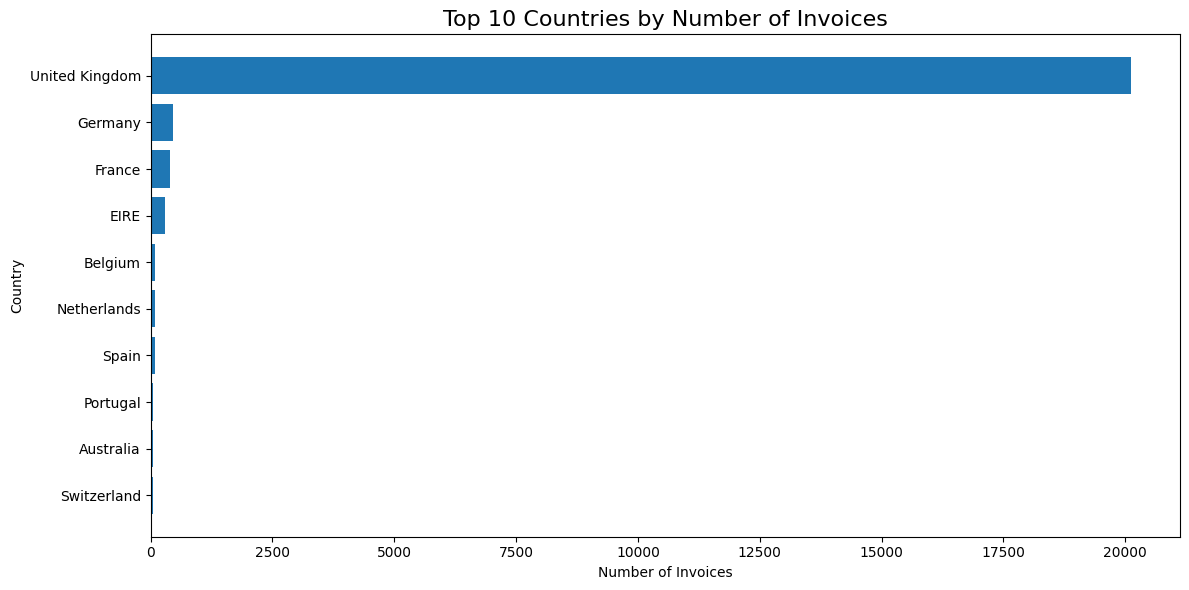

In [86]:
top_10_invoice_countries = country_invoices.head(10).sort_values()

plt.figure(figsize=(12, 6))
plt.barh(top_10_invoice_countries.index,
         top_10_invoice_countries.values)

plt.title('Top 10 Countries by Number of Invoices', fontsize=16)
plt.xlabel('Number of Invoices')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

In [87]:
# Top 10 products by quantity sold

product_quantity = (
    df_clean[df_clean['Quantity'] > 0]
    .groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Products by Quantity Sold:")
print(product_quantity.head(10))

Top 10 Products by Quantity Sold:
Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48375
WHITE HANGING HEART T-LIGHT HOLDER    37876
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
Unknown Product                       32547
RABBIT NIGHT LIGHT                    30739
Name: Quantity, dtype: int64


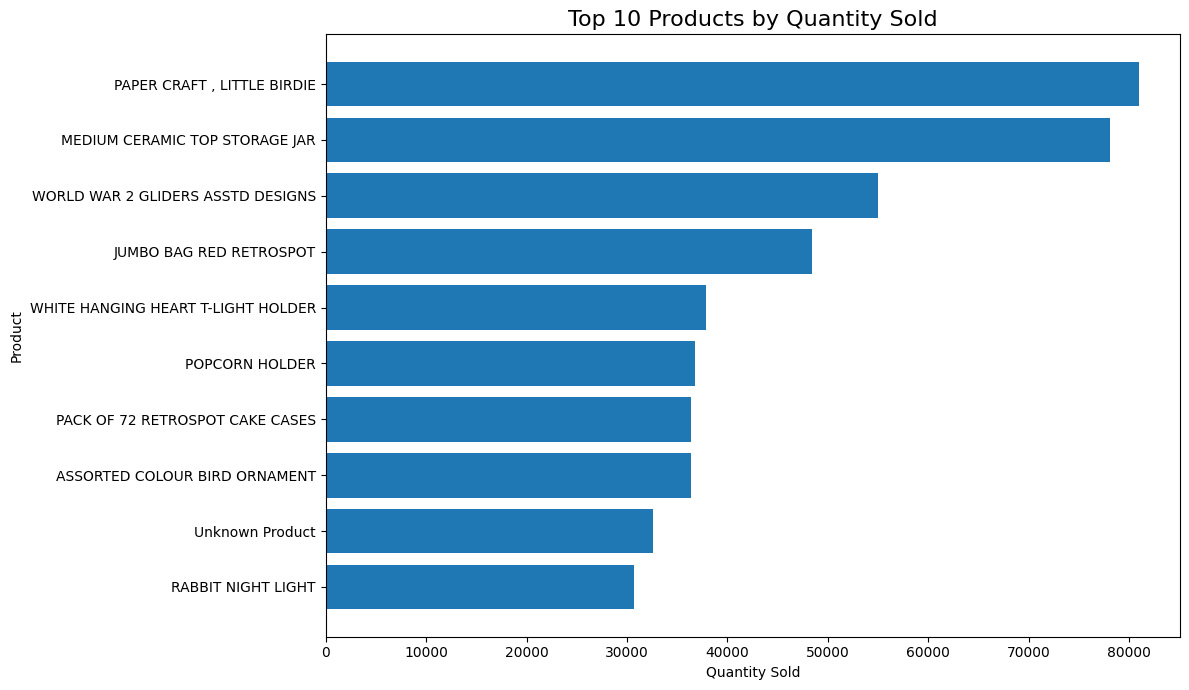

In [88]:
top_10_quantity = product_quantity.head(10).sort_values()

plt.figure(figsize=(12, 7))
plt.barh(top_10_quantity.index, top_10_quantity.values)

plt.title('Top 10 Products by Quantity Sold', fontsize=16)
plt.xlabel('Quantity Sold')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

In [89]:
print("Total Revenue:", round(df_clean['Sales'].sum(), 2), "GBP")

print("Total Quantity Sold:",
      df_clean.loc[df_clean['Quantity'] > 0, 'Quantity'].sum())

print("Total Invoices:", df_clean['InvoiceNo'].nunique())

print("Number of Countries:", df_clean['Country'].nunique())

print("Number of Products:", df_clean['Description'].nunique())

print("Analysis Period:",
      df_clean['InvoiceDate'].min(),
      "to",
      df_clean['InvoiceDate'].max())

Total Revenue: 10642110.8 GBP
Total Quantity Sold: 5645017
Total Invoices: 22062
Number of Countries: 38
Number of Products: 4208
Analysis Period: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [90]:
highest_invoice_id = (
    df_clean.groupby('InvoiceNo')['Sales']
    .sum()
    .idxmax()
)

print("Highest Invoice Number:", highest_invoice_id)

print(
    df_clean[df_clean['InvoiceNo'] == highest_invoice_id][
        ['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'Sales']
    ]
)

Highest Invoice Number: 581483
       InvoiceNo                  Description  Quantity  UnitPrice     Sales
540421    581483  PAPER CRAFT , LITTLE BIRDIE     80995       2.08  168469.6


In [91]:
df_clean[df_clean['InvoiceNo'] == '581483']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,Month


In [92]:
print("InvoiceNo data type:", df_clean['InvoiceNo'].dtype)

print(
    df_clean[df_clean['InvoiceNo'].astype(str).str.strip() == '581483']
)


InvoiceNo data type: object
       InvoiceNo StockCode                  Description  Quantity  \
540421    581483     23843  PAPER CRAFT , LITTLE BIRDIE     80995   

               InvoiceDate  UnitPrice  CustomerID         Country     Sales  \
540421 2011-12-09 09:15:00       2.08     16446.0  United Kingdom  168469.6   

          Month  
540421  2011-12  


# 4. Results and Key Findings

This section presents the main findings obtained from analyzing the Online Retail dataset. The results highlight overall sales performance, product performance, country-level sales distribution, and monthly sales trends.

## 4.1 Overall Sales Performance

The analysis revealed that the cleaned dataset contains 527,388 transaction records covering the period from December 1, 2010, to December 9, 2011. During this period, the business generated total revenue of **£10,642,110.80**, with approximately **5,645,017 units sold** across 38 countries and 4,208 different product descriptions.

The dataset contains 22,062 unique invoices, with an average invoice value of £482.37. The highest recorded invoice value was £168,469.60, associated with invoice number 581483. This unusually high transaction was retained because there was insufficient evidence to classify it as an error.

## 4.2 Sales Performance by Country

The country-level analysis showed that the United Kingdom was the leading market, generating total sales of **£9,001,744.09**, representing the largest share of overall revenue. It was followed by the Netherlands with £285,446.34, EIRE with £283,140.52, and Germany with £228,678.40.

The United Kingdom also recorded the highest number of invoices, with 20,120 invoices, compared with 457 in Germany and 392 in France. These findings indicate that the business's sales activity was heavily concentrated in the United Kingdom, making it its most important market during the analyzed period.

## 4.3 Product Performance Analysis

The product analysis revealed differences between the products generating the highest revenue and those sold in the largest quantities.

In terms of revenue, **DOTCOM POSTAGE** ranked first, generating £206,248.77, followed by **REGENCY CAKESTAND 3 TIER** with £174,156.54 and **PAPER CRAFT, LITTLE BIRDIE** with £168,469.60.

In terms of quantity sold, **PAPER CRAFT, LITTLE BIRDIE** ranked first, with 80,995 units, followed by **MEDIUM CERAMIC TOP STORAGE JAR** with 78,033 units and **WORLD WAR 2 GLIDERS ASSTD DESIGNS** with 54,951 units.

These findings demonstrate that the products generating the highest revenue are not necessarily the products sold in the largest quantities. They also highlight the importance of examining both sales value and sales volume when evaluating product performance.

## 4.4 Monthly Sales Trends

The monthly sales analysis revealed noticeable variations in revenue throughout the analyzed period. November 2011 recorded the highest monthly sales, reaching **£1,503,866.78**, followed by October 2011 with £1,151,263.73 and September 2011 with £1,056,435.19.

In contrast, February 2011 recorded the lowest monthly sales, amounting to **£522,545.56**.

The results indicate an increase in sales activity during the final months of 2011, particularly between September and November. However, December 2011 should be interpreted carefully because the dataset ends on December 9, 2011, and therefore does not represent a complete month.

## 4.5 Data Quality Observations and Limitations

During the data-cleaning process, 5,268 duplicate records were removed, along with cancelled invoices and two records containing negative unit prices. Missing product descriptions were replaced with the label "Unknown Product", while missing customer IDs were retained because customer-level analysis was not the main focus of this project.

The analysis also identified 1,336 records with negative quantities. However, all these records had zero unit prices, resulting in no monetary impact on the calculated revenue. Therefore, total revenue and net sales were both £10,642,110.80.

One unusually large invoice, valued at £168,469.60, was retained because there was insufficient evidence to confirm that it represented an error. These observations should be considered when interpreting the results.

# 5. Conclusion and Recommendations

## 5.1 Conclusion

This project analyzed the Online Retail dataset using Python and its main data analysis libraries. The analysis provided insights into sales performance, product demand, geographical distribution, and monthly sales trends.

The findings showed that the United Kingdom was the largest market in terms of both revenue and invoice count. The analysis also revealed that PAPER CRAFT, LITTLE BIRDIE was the most sold product by quantity, while DOTCOM POSTAGE generated the highest revenue among the product descriptions. November 2011 recorded the highest monthly sales, whereas February 2011 recorded the lowest.

Overall, the project demonstrated how data analysis can transform raw transaction records into meaningful information that supports business understanding and decision-making.

## 5.2 Recommendations

Based on the analysis, the following recommendations are suggested:

1. **Strengthen the UK Market:** Maintain the business's strong presence in the United Kingdom while exploring opportunities to expand in other countries.

2. **Improve Product Management:** Monitor high-demand products and ensure sufficient stock to meet customer demand.

3. **Review Revenue Performance:** Evaluate products that generate high revenue and identify opportunities to improve the profitability of other products.

4. **Monitor Seasonal Trends:** Study the increase in sales during September, October, and November to support future sales planning and inventory management.

5. **Improve Data Quality:** Continue monitoring missing values, duplicate records, and unusual transactions to improve the accuracy of future analyses.

# 6. References

1. Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

2. The pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/

3. NumPy Developers. (n.d.). *NumPy documentation*. https://numpy.org/doc/

4. Matplotlib Development Team. (n.d.). *Matplotlib documentation*. https://matplotlib.org/stable/

5. Waskom, M. (n.d.). *seaborn: Statistical data visualization*. https://seaborn.pydata.org/

In [93]:
# Save the cleaned dataset

df_clean.to_csv("cleaned_online_retail.csv", index=False)

print("Final cleaned dataset saved successfully!")
print("Dataset shape:", df_clean.shape)

Final cleaned dataset saved successfully!
Dataset shape: (527388, 10)


In [94]:
from google.colab import files
files.download("cleaned_online_retail.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [95]:
import zipfile

with zipfile.ZipFile("cleaned_online_retail.zip", "w", zipfile.ZIP_DEFLATED) as zipf:
    zipf.write("cleaned_online_retail.csv")

import os
print("ZIP file size:", round(os.path.getsize("cleaned_online_retail.zip") / (1024 * 1024), 2), "MB")

ZIP file size: 8.63 MB


In [96]:
from google.colab import files
files.download("cleaned_online_retail.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>